# 03 - Baseline Models: Naive and Linear Regression

Before trying the five frameworks we need something to compare them against.

1. **Naive ("no change") forecast:** next week's yield = today's yield. It has no parameters and needs no training. Because yields move so little in a week (see notebook 02), it's a surprisingly strong benchmark.
2. **Linear regression:** the simplest real model, and a natural benchmark for the frameworks.

Every model in this project is run in three experiments (see notebook 02):

| Experiment | Target | Inputs |
|---|---|---|
| A | yield level 5 days ahead | all 23 features |
| B | 5-day change | all 23 features |
| C | 5-day change | 15 features (no raw yield levels) |

All metrics are computed on the yield level of the **test period (Jan 2023 - Sep 2026)**.

In [1]:
import sys
import time
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

from src import config, features, evaluate, plots

plots.setup()
pd.set_option("display.precision", 4)

df = features.load_dataset()
print("All features:", len(features.ALL_FEATURES))
print("Without yield levels:", len(features.NO_LEVEL_FEATURES), features.NO_LEVEL_FEATURES)

data, mode = features.get_experiment(df, "B")
for name in ["train", "val", "test"]:
    X = data[name]["X"]
    print(f"{name:<5} {len(X):>5} rows   {X.index.min().date()} to {X.index.max().date()}")

All features: 23
Without yield levels: 15 ['GOV_PCT', 'HOM_PCT', 'FOR_PCT', 'BAA10Y', 'SLOPE_10Y_2Y', 'SLOPE_10Y_3M', 'CURVATURE', 'DGS1MO_CHG5', 'DGS5_CHG5', 'DGS30_CHG5', 'VIX', 'SP500_RET5', 'BRENT_RET5', 'GOLD_RET5', 'DXY_RET5']
train  2993 rows   2010-01-11 to 2021-12-23
val     244 rows   2022-01-03 to 2022-12-22
test    932 rows   2023-01-03 to 2026-09-23


## 1. Naive forecast

The prediction is simply today's yield, so it's the same in every experiment.

In [2]:
test = data["test"]
naive_pred = test["today"].values
naive_metrics = evaluate.evaluate(test["future"], naive_pred, test["today"])
for exp in config.EXPERIMENTS:
    evaluate.save_predictions("Naive", exp, config.SEED, test, naive_pred)
evaluate.save_run_info("Naive", {"train_seconds": 0.0, "lines_of_code": 1, "hyperparameters": 0})
naive_metrics

,RMSE,MAE,R2,R2_change,skill_vs_naive,direction_acc
target,,,,,,
1M,0.1468,0.0616,0.9560,-7.8184e-05,0.0,NaN
5Y,0.1379,0.1050,0.8402,-2.3175e-03,0.0,NaN
30Y,0.1111,0.0866,0.9322,-7.5306e-03,0.0,NaN


**Observations**
- The naive forecast misses next week's yield by about 11-15 basis points (RMSE: 1M 0.147, 5Y 0.138, 30Y 0.111 percentage points).
- Even so, its R² on levels is 0.96 (1M), 0.84 (5Y) and 0.93 (30Y), without learning anything. A high R² on levels says very little here.
- R² on the change is about 0, because it always predicts a change of zero, and its direction accuracy is undefined (it never predicts up or down).
- Every other model is judged by `skill_vs_naive` = 1 − RMSE_model / RMSE_naive. A positive value means the model beats naive.

## 2. Linear regression

The features are standardised (mean 0, standard deviation 1) using the training data only, so the coefficients can be compared with each other.

In [3]:
def train_linear(X_train, y_train):
    scaler = StandardScaler().fit(X_train)
    model = LinearRegression().fit(scaler.transform(X_train), y_train)
    return scaler, model


results = {}
for exp in config.EXPERIMENTS:
    data, mode = features.get_experiment(df, exp)
    train, test = data["train"], data["test"]

    start = time.time()
    scaler, model = train_linear(train["X"], train["y"])
    train_time = time.time() - start

    pred_level = evaluate.to_level(model.predict(scaler.transform(test["X"])), test["today"], mode)
    results[exp] = evaluate.evaluate(test["future"], pred_level, test["today"])
    evaluate.save_predictions("Linear", exp, config.SEED, test, pred_level)
    print(f"\n=== Linear regression, experiment {config.EXPERIMENT_NAMES[exp]} ===")
    print(results[exp].round(4))
    if exp == "C":
        model_c = model

evaluate.save_run_info("Linear", {"train_seconds": train_time,
                                  "lines_of_code": evaluate.count_lines(train_linear),
                                  "hyperparameters": 0})


=== Linear regression, experiment A: level, all features ===
          RMSE     MAE      R2  R2_change  skill_vs_naive  direction_acc
target                                                                  
1M      0.1326  0.0692  0.9641     0.1843          0.0969         0.6046
5Y      0.1882  0.1547  0.7023    -0.8675         -0.3650         0.4533
30Y     0.2817  0.2578  0.5642    -5.4803         -1.5361         0.4467

=== Linear regression, experiment B: change, all features ===
          RMSE     MAE      R2  R2_change  skill_vs_naive  direction_acc
target                                                                  
1M      0.1326  0.0692  0.9641     0.1843          0.0969         0.6046
5Y      0.1882  0.1547  0.7023    -0.8675         -0.3650         0.4533
30Y     0.2817  0.2578  0.5642    -5.4803         -1.5361         0.4467

=== Linear regression, experiment C: change, no yield levels ===
          RMSE     MAE      R2  R2_change  skill_vs_naive  direction_acc
target

**Observations**
- **Experiments A and B give exactly the same numbers.** This is not a bug. Today's 1M, 5Y and 30Y yields are among the inputs, so predicting `future` and predicting `future − today` are the same least-squares problem: the coefficient on today's yield just shifts by 1. For linear regression, changing only the target makes no difference. It does for XGBoost and the neural nets.
- With all 23 features, linear regression is **much worse than naive** for the 5Y (skill −0.37) and 30Y (−1.54), but 10% better for the 1M. It learned relationships between yield *levels* and next week's move from 2010-2021, and these produced large systematic errors in 2023-2026, when yields were far higher.
- **Experiment C** (no raw yield levels as inputs) removes the problem: skill is between −0.01 and −0.04 for all three targets, almost exactly as good as naive but not better. Direction accuracy is 51-57%.

## 3. Which features help? (chosen on the validation set)

To check that experiment C's choice of inputs is reasonable, linear regression is trained on the change target with different feature groups. The **validation** skill (2022) is what we would use to choose. The test skill is only shown for reference.

In [4]:
feature_groups = {
    "case study (12)": features.BOOK_FEATURES,
    "+ curve shape & momentum (18)": features.BOOK_FEATURES + features.CURVE_FEATURES,
    "+ Yahoo market data = all (23)": features.ALL_FEATURES,
    "all except yield levels (15)": features.NO_LEVEL_FEATURES,
}
rows = []
for group, cols in feature_groups.items():
    split = features.make_splits(df, cols, "change")
    scaler, model = train_linear(split["train"]["X"], split["train"]["y"])
    row = {"features": group}
    for part in ["val", "test"]:
        s = split[part]
        pred = evaluate.to_level(model.predict(scaler.transform(s["X"])), s["today"], "change")
        skill = evaluate.evaluate(s["future"], pred, s["today"])["skill_vs_naive"]
        for name, value in skill.items():
            row[f"{part} {name}"] = value
    rows.append(row)
ablation = pd.DataFrame(rows).set_index("features")
ablation.round(3)

,val 1M,val 5Y,val 30Y,test 1M,test 5Y,test 30Y
features,,,,,,
case study (12),-0.130,0.011,-0.126,0.055,-0.390,-1.660
+ curve shape & momentum (18),-0.105,0.008,-0.099,0.112,-0.368,-1.526
+ Yahoo market data = all (23),-0.055,0.010,-0.118,0.097,-0.365,-1.536
all except yield levels (15),0.140,0.022,0.018,-0.021,-0.012,-0.037


**Observations**
- On the validation year (2022), the curve-shape and Yahoo market features help a little for the 1M (skill from −0.13 to −0.055). But **only removing the raw yield levels makes all three validation skills positive** (+0.14, +0.02, +0.02). So the validation set alone leads to the same inputs as experiment C. We didn't need to look at the test set to choose them.
- On the test set, removing the levels avoids the big losses for the 5Y and 30Y, but it doesn't turn them into gains.
- For the 1M, the level inputs helped on the test set (+0.10) but hurt on validation, so we couldn't have relied on that choice in advance.

## 4. What did linear regression learn? (experiment C)

Since the inputs are standardised, each coefficient shows how many percentage points the predicted 5-day change moves when that feature goes up by one standard deviation.

In [5]:
coefs = pd.DataFrame(model_c.coef_.T, index=features.NO_LEVEL_FEATURES,
                     columns=[config.TARGET_NAMES[t] for t in config.TARGETS])
coefs["mean |coef|"] = coefs.abs().mean(axis=1)
coefs = coefs.sort_values("mean |coef|", ascending=False)
evaluate.save_importance("Linear", coefs["mean |coef|"], "mean_abs_coef")
coefs.round(4)

,1M,5Y,30Y,mean |coef|
SLOPE_10Y_3M,0.0614,0.0270,0.0335,0.0406
SLOPE_10Y_2Y,-0.0568,-0.0225,-0.0333,0.0375
DGS30_CHG5,-0.0036,-0.0128,-0.0277,0.0147
CURVATURE,-0.0100,-0.0165,-0.0146,0.0137
GOV_PCT,0.0088,0.0130,0.0055,0.0091
DGS5_CHG5,0.0025,0.0038,0.0166,0.0076
DXY_RET5,0.0023,-0.0031,-0.0106,0.0053
BRENT_RET5,0.0033,0.0022,0.0084,0.0046
VIX,-0.0070,-0.0044,-0.0024,0.0046
SP500_RET5,0.0039,0.0014,-0.0081,0.0045


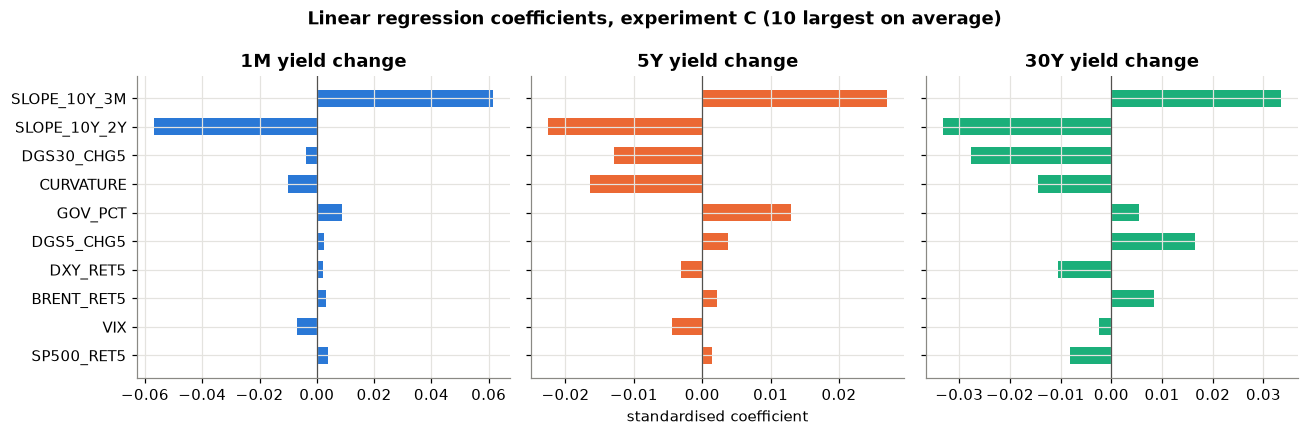

In [6]:
top = coefs.head(10).iloc[::-1]
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, t in zip(axes, config.TARGETS):
    name = config.TARGET_NAMES[t]
    ax.barh(top.index, top[name], color=plots.TARGET_COLORS[t], height=0.6)
    ax.axvline(0, color="#52514e", linewidth=0.8)
    ax.set_title(f"{name} yield change")
axes[1].set_xlabel("standardised coefficient")
fig.suptitle("Linear regression coefficients, experiment C (10 largest on average)", fontweight="bold")
plt.tight_layout()
plots.save(fig, "03_linear_coefficients")
plt.show()

**Observations**
- The two slope features have the biggest coefficients, with **opposite signs**. They're strongly correlated, so together the model is really using their difference: (10Y − 3M) − (10Y − 2Y) = **2Y − 3M**. When 2-year yields are above 3-month yields, the market expects the Fed to raise rates, and the model predicts short-term yields will go up. That makes economic sense.
- `DGS30_CHG5` is negative for the 30Y: after a big move in one week, the 30Y tends to move back a little the next week.
- All coefficients are small. One standard deviation of any feature changes the predicted weekly move by at most about 6 bp for the 1M and 2-3 bp for the 5Y and 30Y. The model stays close to the naive forecast.

## 5. Predicted vs actual 5-day change (test period, experiment C)

Plotting levels isn't very informative here, because every forecast is close to today's yield. Plotting the predicted **change** against the actual change shows what the model really does.

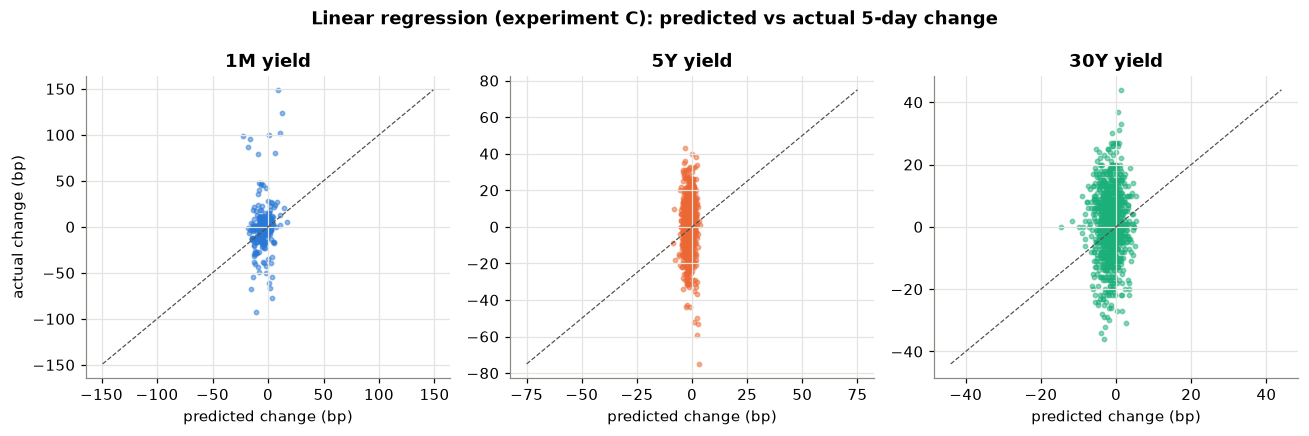

In [7]:
pred = pd.read_csv(config.PRED_DIR / f"Linear_C_seed{config.SEED}.csv", index_col=0, parse_dates=True)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, t in zip(axes, config.TARGETS):
    actual_chg = (pred[f"{t}_actual"] - pred[f"{t}_today"]) * 100
    pred_chg = (pred[f"{t}_pred"] - pred[f"{t}_today"]) * 100
    ax.scatter(pred_chg, actual_chg, s=8, alpha=0.5, color=plots.TARGET_COLORS[t])
    lim = max(actual_chg.abs().max(), pred_chg.abs().max())
    ax.plot([-lim, lim], [-lim, lim], color="#52514e", linewidth=0.8, linestyle="--")
    ax.set_title(f"{config.TARGET_NAMES[t]} yield")
    ax.set_xlabel("predicted change (bp)")
axes[0].set_ylabel("actual change (bp)")
fig.suptitle("Linear regression (experiment C): predicted vs actual 5-day change", fontweight="bold")
plt.tight_layout()
plots.save(fig, "03_linear_pred_vs_actual")
plt.show()

**Observations**
- The predicted changes stay within a few basis points of zero, while the actual changes range from about −40 to +40 bp (5Y, 30Y) and over ±100 bp for the 1M (May 2023 debt-ceiling spike).
- There's no visible diagonal pattern. The model can't anticipate the large moves, and behaves like a slightly adjusted naive forecast.
- This is the realistic picture for one-week-ahead yield forecasting. It's the benchmark the five frameworks have to beat.